# E8 파생변수 기반 ExtraTrees 하이퍼파라미터 튜닝

기존 `src/features.py`의 E8 파생변수는 유지하고, 앞선 비교에서 로지스틱 회귀보다 높은 점수를 보인 **ExtraTrees**의 하이퍼파라미터를 `RandomizedSearchCV`로 탐색합니다. 불균형 다중분류의 Macro F1에 맞춰 그룹을 고려한 CV 점수를 사용하며, 중복된 변이 프로필은 학습/검증 경계를 넘지 않도록 합니다.

탐색용 그룹 CV와 별도로 남겨 둔 그룹 홀드아웃에서 기본 ExtraTrees와 튜닝 ExtraTrees를 비교합니다. 팀 E8 XGBoost CV 0.450은 다른 실험의 참고 기준일 뿐, 같은 분할 점수로 간주하지 않습니다. **튜닝이 점수를 반드시 높여 주는 것은 아니며**, 홀드아웃 결과로 개선 여부를 확인해야 합니다. `test.csv`는 검증이 끝난 뒤 최종 제출 예측에서만 읽습니다.

In [5]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV
from sklearn.metrics import f1_score, make_scorer, classification_report, ConfusionMatrixDisplay
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

cwd = Path.cwd()
project_root = next((p for p in (cwd, cwd.parent) if (p / "src" / "features.py").is_file()), None)
if project_root is None:
    raise FileNotFoundError("프로젝트 루트에서 src/features.py를 찾을 수 없습니다.")
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.features import build_features, gene_columns

train = pd.read_csv(project_root / "data" / "train.csv")
if "SUBCLASS" not in train.columns:
    raise KeyError("train.csv에 SUBCLASS 타깃 열이 없습니다.")

y_all = train["SUBCLASS"].astype("string").str.strip()
target_valid = y_all.notna() & y_all.ne("")
missing_target_count = int((~target_valid).sum())
train = train.loc[target_valid].reset_index(drop=True)
y = train["SUBCLASS"].astype(str)
genes = gene_columns(train)
if not genes:
    raise ValueError("학습 데이터에서 유전자 입력 열을 찾지 못했습니다.")
missing_gene_cells = int(train[genes].isna().sum().sum())
groups = pd.util.hash_pandas_object(train[genes].fillna("WT"), index=False).to_numpy()

print(f"데이터: {len(train):,}행, {len(genes):,}개 유전자, {y.nunique()}개 암종")
print(f"타깃 결측 제거: {missing_target_count:,}행; 유전자 결측 셀: {missing_gene_cells:,}개")
print(f"완전 동일 변이 프로필: {pd.Series(groups).duplicated().sum():,}개 중복 행")
display(y.value_counts().rename("sample_count").to_frame())

데이터: 6,201행, 4,384개 유전자, 26개 암종
타깃 결측 제거: 0행; 유전자 결측 셀: 0개
완전 동일 변이 프로필: 565개 중복 행


,sample_count
SUBCLASS,
BRCA,786
KIPAN,515
GBMLGG,461
STES,379
KIRC,334
THCA,324
SKCM,276
PRAD,266
OV,253


### 데이터 점검

실행 결과에서 행/유전자/암종 수, 타깃·유전자 결측, 동일 변이 프로필 중복 수와 클래스별 표본 수를 확인합니다. 타깃이 비어 있는 행만 제외하고, 유전자 결측은 프로젝트의 E8 전처리 규칙에 따라 WT로 처리합니다. 동일 프로필은 그룹으로 묶어 검증 폴드 간 분리를 방지합니다. 데이터 값이나 모델 점수는 셀을 실행한 뒤에만 해석합니다.

In [6]:
SEED = 42
BASELINE_E8_MACRO_F1 = 0.450
class_labels = sorted(y.unique())

# Hold out one complete profile-group fold for a final, untouched comparison.
outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_idx, valid_idx = next(outer_cv.split(train, y, groups))
dev = train.iloc[dev_idx].reset_index(drop=True)
valid = train.iloc[valid_idx].reset_index(drop=True)
y_dev = y.iloc[dev_idx].reset_index(drop=True)
y_valid = y.iloc[valid_idx].reset_index(drop=True)
groups_dev = groups[dev_idx]

# E8 feature selection uses development data only; validation labels are never used.
X_dev, X_valid = build_features(dev, valid, level="E8")
if list(X_dev.columns) != list(X_valid.columns):
    raise ValueError("학습/검증 파생변수 열이 일치하지 않습니다.")

scorer = make_scorer(
    f1_score,
    labels=class_labels,
    average="macro",
    zero_division=0,
)
search_cv = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED + 1)
base_params = {
    "n_estimators": 400,
    "max_features": "sqrt",
    "min_samples_leaf": 2,
    "class_weight": "balanced",
}

# Explore tree size, depth, feature subsampling and leaf regularization.
param_distributions = {
    "n_estimators": [250, 400, 600],
    "max_features": ["sqrt", 0.15, 0.30, 0.50],
    "max_depth": [None, 20, 35, 50],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 3, 5],
    "class_weight": ["balanced", None],
}
search = RandomizedSearchCV(
    estimator=ExtraTreesClassifier(random_state=SEED, n_jobs=-1),
    param_distributions=param_distributions,
    n_iter=16,
    scoring=scorer,
    cv=search_cv,
    refit=True,
    random_state=SEED,
    n_jobs=1,
    verbose=1,
    return_train_score=True,
)
search.fit(X_dev, y_dev, groups=groups_dev)

baseline_model = ExtraTreesClassifier(
    **base_params,
    random_state=SEED,
    n_jobs=-1,
)
baseline_model.fit(X_dev, y_dev)
baseline_valid_predictions = baseline_model.predict(X_valid)
tuned_valid_predictions = search.best_estimator_.predict(X_valid)
baseline_valid_f1 = f1_score(
    y_valid, baseline_valid_predictions,
    labels=class_labels, average="macro", zero_division=0,
)
tuned_valid_f1 = f1_score(
    y_valid, tuned_valid_predictions,
    labels=class_labels, average="macro", zero_division=0,
)

best_params = search.best_params_.copy()
best_model_name = "ExtraTrees_tuned"
best_valid_predictions = tuned_valid_predictions
best_valid_f1 = float(tuned_valid_f1)
model_summary = pd.DataFrame([
    {"model": "ExtraTrees baseline", "validation_macro_f1": baseline_valid_f1},
    {"model": "ExtraTrees tuned", "validation_macro_f1": tuned_valid_f1},
])

print(f"Development: {len(dev):,}; untouched grouped validation: {len(valid):,}; features: {X_dev.shape[1]:,}")
print(f"Best grouped-CV Macro F1: {search.best_score_:.4f}")
print(f"Tuned parameters: {best_params}")
print(f"Untouched validation Macro F1 — baseline: {baseline_valid_f1:.4f}; tuned: {tuned_valid_f1:.4f}")
print(f"Change on the same holdout: {tuned_valid_f1 - baseline_valid_f1:+.4f}")
if tuned_valid_f1 > baseline_valid_f1:
    print("이 홀드아웃에서는 튜닝 모델이 기본 설정보다 높았습니다. 다른 분할/리더보드에서도 향상된다고 보장되지는 않습니다.")
else:
    print("이 홀드아웃에서는 튜닝 모델이 기본 설정을 넘지 못했습니다. 성능 개선으로 간주하지 마세요.")
if tuned_valid_f1 <= BASELINE_E8_MACRO_F1:
    print(f"참고: 기록된 팀 E8 XGBoost CV {BASELINE_E8_MACRO_F1:.3f}보다 낮지만, CV와 단일 홀드아웃은 직접 비교할 수 없습니다.")

tuning_results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score").loc[:, [
    "rank_test_score", "mean_test_score", "std_test_score", "mean_train_score", "params"
]].head(10)
display(model_summary)
display(tuning_results)

Fitting 4 folds for each of 16 candidates, totalling 64 fits
Development: 4,960; untouched grouped validation: 1,241; features: 4,634
Best grouped-CV Macro F1: 0.3940
Tuned parameters: {'n_estimators': 400, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.15, 'max_depth': 35, 'class_weight': 'balanced'}
Untouched validation Macro F1 — baseline: 0.4240; tuned: 0.4060
Change on the same holdout: -0.0180
이 홀드아웃에서는 튜닝 모델이 기본 설정을 넘지 못했습니다. 성능 개선으로 간주하지 마세요.
참고: 기록된 팀 E8 XGBoost CV 0.450보다 낮지만, CV와 단일 홀드아웃은 직접 비교할 수 없습니다.


,model,validation_macro_f1
0,ExtraTrees baseline,0.423960
1,ExtraTrees tuned,0.406001


,rank_test_score,mean_test_score,std_test_score,mean_train_score,params
9,1,0.394017,0.011740,0.873069,"{'n_estimators': 400, 'min_samples_split': 5, ..."
15,2,0.390673,0.011642,0.777370,"{'n_estimators': 250, 'min_samples_split': 10,..."
7,3,0.389967,0.018306,0.911228,"{'n_estimators': 600, 'min_samples_split': 5, ..."
8,4,0.374879,0.010579,0.717274,"{'n_estimators': 250, 'min_samples_split': 2, ..."
10,5,0.369356,0.019461,0.931638,"{'n_estimators': 400, 'min_samples_split': 2, ..."
14,6,0.368322,0.010929,0.932571,"{'n_estimators': 250, 'min_samples_split': 2, ..."
5,7,0.363210,0.008288,0.698409,"{'n_estimators': 600, 'min_samples_split': 2, ..."
6,8,0.362714,0.008766,0.916164,"{'n_estimators': 600, 'min_samples_split': 10,..."
12,9,0.360012,0.009080,0.836264,"{'n_estimators': 250, 'min_samples_split': 10,..."
3,10,0.359847,0.008317,0.617693,"{'n_estimators': 250, 'min_samples_split': 10,..."


### 하이퍼파라미터 탐색과 홀드아웃 검증

내부 4-fold `StratifiedGroupKFold`에서 Macro F1을 최대화하도록 16개 조합을 무작위 탐색합니다. `max_features`, 트리 깊이, 트리 수, 리프/분할 최소 표본 수, 클래스 가중치를 조정해 과적합과 소수 클래스 성능의 균형을 찾습니다. 탐색 후에는 튜닝 설정과 기존 기본 설정을 **동일한 미사용 그룹 홀드아웃**에서 비교합니다. 튜닝 CV 점수는 선택에 사용된 점수이므로 독립 성능 추정치로 취급하지 않고, 홀드아웃 Macro F1과 기본 모델 대비 변화량을 우선 확인합니다.

,f1_score
SARC,0.158730
PAAD,0.166667
LUAD,0.169492
BLCA,0.235294
PRAD,0.254902
KIPAN,0.255814
HNSC,0.270270
PCPG,0.278689
LAML,0.340426
TGCT,0.344086


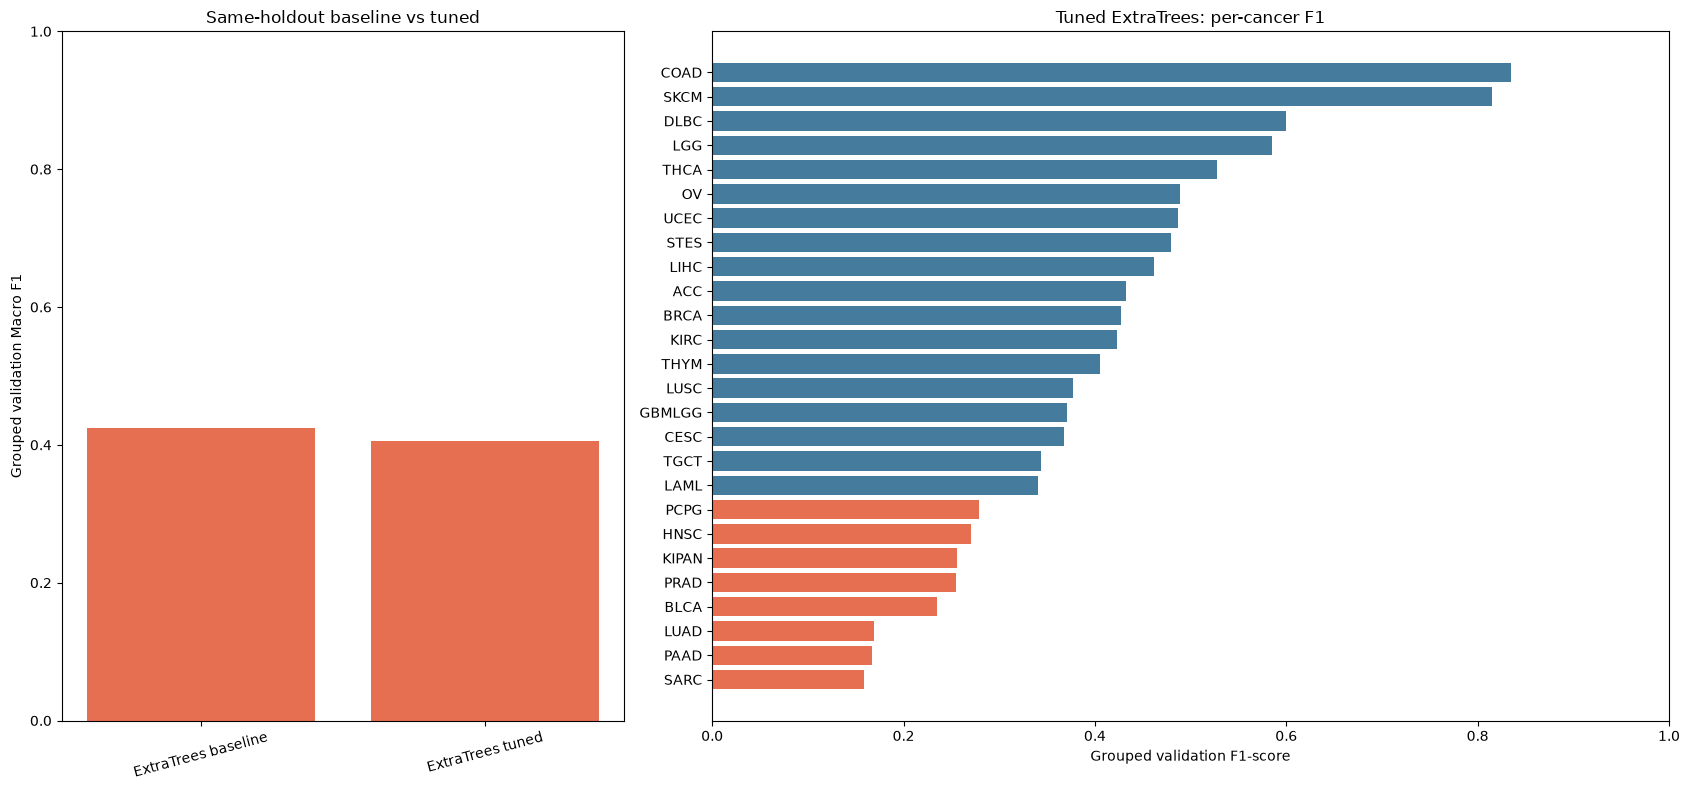

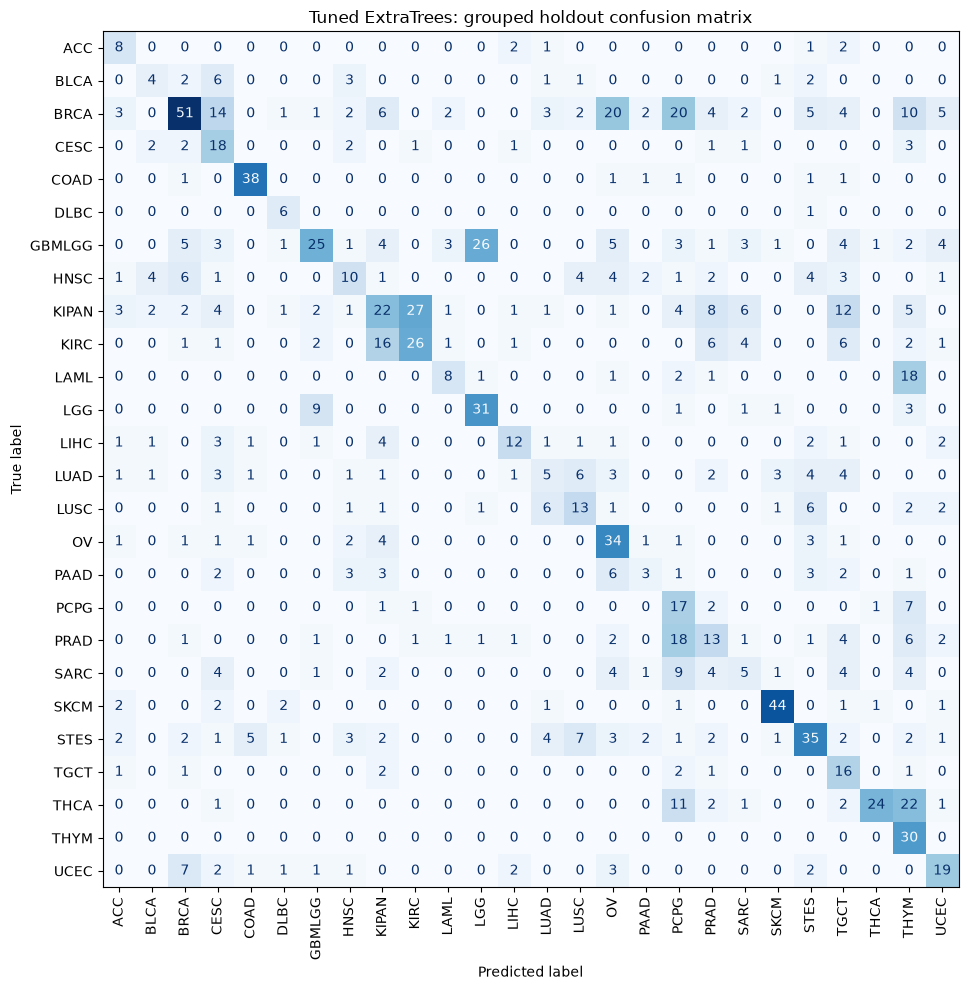

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(17, 8), gridspec_kw={"width_ratios": [1, 1.7]})
bar_colors = ["#2a9d8f" if score > baseline_valid_f1 else "#e76f51" for score in model_summary["validation_macro_f1"]]
axes[0].bar(model_summary["model"], model_summary["validation_macro_f1"], color=bar_colors)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("Grouped validation Macro F1")
axes[0].set_title("Same-holdout baseline vs tuned")
axes[0].tick_params(axis="x", rotation=15)

best_report = classification_report(
    y_valid,
    best_valid_predictions,
    labels=class_labels,
    output_dict=True,
    zero_division=0,
)
class_f1 = pd.Series({label: best_report[label]["f1-score"] for label in class_labels}, name="f1_score").sort_values()
display(class_f1.to_frame())
axes[1].barh(class_f1.index, class_f1.values, color=["#e76f51" if score < 0.30 else "#457b9d" for score in class_f1.values])
axes[1].set_xlim(0, 1)
axes[1].set_xlabel("Grouped validation F1-score")
axes[1].set_title("Tuned ExtraTrees: per-cancer F1")
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(11, 10))
ConfusionMatrixDisplay.from_predictions(
    y_valid,
    best_valid_predictions,
    labels=class_labels,
    display_labels=class_labels,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False,
    ax=ax,
)
ax.set_title("Tuned ExtraTrees: grouped holdout confusion matrix")
fig.tight_layout()
plt.show()

### 암종별 오류 확인

검증 홀드아웃의 암종별 F1과 혼동행렬로 튜닝 후에도 어려운 하위 유형을 확인합니다. 튜닝 점수가 기본 설정보다 높더라도 일부 암종 성능이 크게 낮거나 CV-홀드아웃 간 차이가 크면 과적합 가능성이 있으므로, 이 결과 하나만으로 모델을 확정하지 말고 최종 리더보드 점수와 함께 판단합니다.

In [8]:
test = pd.read_csv(project_root / "data" / "test.csv")
X_train_final, X_test_final = build_features(train, test, level="E8")
if list(X_train_final.columns) != list(X_test_final.columns):
    raise ValueError("최종 학습/테스트 파생변수 열이 일치하지 않습니다.")

final_model = ExtraTreesClassifier(
    **best_params,
    random_state=SEED,
    n_jobs=-1,
)
final_model.fit(X_train_final, y)
test_predictions = final_model.predict(X_test_final)
sample_path = project_root / "data" / "sample_submission.csv"
submission = pd.read_csv(sample_path)
if "ID" in submission.columns and "ID" in test.columns:
    if test["ID"].duplicated().any():
        raise ValueError("test.csv의 ID가 중복되어 제출 행에 안전하게 매핑할 수 없습니다.")
    predictions_by_id = pd.Series(test_predictions, index=test["ID"])
    submission["SUBCLASS"] = submission["ID"].map(predictions_by_id)
    if submission["SUBCLASS"].isna().any():
        raise ValueError("sample_submission.csv의 일부 ID에 대한 예측을 찾지 못했습니다.")
elif len(submission) == len(test_predictions):
    submission["SUBCLASS"] = test_predictions
else:
    raise ValueError("sample_submission.csv와 test.csv의 행 수 또는 ID 열을 확인하세요.")

output_path = project_root / "submissions" / "1109_myeongseok_extratrees_tuned_e8.csv"
submission.to_csv(output_path, index=False, encoding="utf-8-sig")
print(f"최종 모델: ExtraTrees; 탐색 파라미터: {best_params}")
print(f"Grouped holdout Macro F1: {best_valid_f1:.4f}; 기본 설정 대비 {best_valid_f1 - baseline_valid_f1:+.4f}")
print(f"제출 파일 저장: {output_path}")
print("리더보드 점수는 대회 제출 후 별도로 기록하세요.")

최종 모델: ExtraTrees; 탐색 파라미터: {'n_estimators': 400, 'min_samples_split': 5, 'min_samples_leaf': 1, 'max_features': 0.15, 'max_depth': 35, 'class_weight': 'balanced'}
Grouped holdout Macro F1: 0.4060; 기본 설정 대비 -0.0180
제출 파일 저장: c:\AI수업\데이콘과제\암종 분류\submissions\1109_myeongseok_extratrees_tuned_e8.csv
리더보드 점수는 대회 제출 후 별도로 기록하세요.


### Q&A
- 어떤 튜닝을 적용하나요? ExtraTrees에서 트리 수, 최대 깊이, 특성 샘플링 비율, 분할/리프 최소 표본 수, 클래스 가중치를 그룹 4-fold CV Macro F1 기준으로 탐색합니다.
- 성능이 실제로 향상되었나요? 실행 후 동일한 그룹 홀드아웃의 기본 설정 대비 점수 변화로 판단합니다. 하이퍼파라미터 탐색만으로 향상이 보장되지는 않습니다.

### Data Analysis Key Findings
- 이전 실행 결과에서 기본 ExtraTrees의 grouped OOF Macro F1은 0.422985였고, 팀 E8 XGBoost 로그 기준은 0.450입니다. 검증 방식/분할이 다르면 직접 비교할 수 없으므로 이번에는 동일 홀드아웃의 튜닝 전후 차이를 별도로 계산합니다.
- 새로운 탐색 결과와 홀드아웃 점수는 셀 실행 전에는 아직 확인되지 않았습니다. 실행 후 상위 CV 조합, 기본 설정 대비 홀드아웃 변화, 암종별 F1을 확인하세요.

### Insights or Next Steps
- 노트북 셀을 순서대로 실행한 뒤 튜닝 점수가 홀드아웃에서도 기본 설정을 넘는지 확인하세요. 넘지 못하면 이 튜닝 결과를 성능 개선으로 채택하지 마세요.
- 검증 결과가 유망하면 제출 파일을 대회에 제출하고, 리더보드 점수 및 설정을 실험 로그에 기록하세요.